This notebook serves as a draft and ideation space prior to the automated training pipeline.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_parquet("../data/vietnam_rice_dataset_2015_2025.parquet")

df.head()

,VH_VV_ratio_mean,VH_max,VH_mean,VH_min,VH_range,VV_max,VV_mean,VV_min,VV_range,precip_total_mm,temp_mean_c,macro_region,planted_area_ha,production_tons,yield_ton_ha,province_name,year,season
0,-6.379569,-13.731947,-17.018732,-21.186979,7.455031,-7.076649,-10.639163,-15.221711,8.145062,184.313428,27.078027,Mekong River Delta,227.2,1569.7,6.71,Long An,2015,spring
1,-6.767354,-13.347810,-15.764152,-18.815880,5.468069,-6.270434,-8.996798,-12.147528,5.877095,684.562912,28.470341,Mekong River Delta,283.9,1331.0,4.69,Long An,2015,autumn
2,-7.440613,-13.339282,-17.567925,-21.703117,8.363835,-6.287126,-10.127312,-14.305305,8.018180,787.565689,27.049146,Mekong River Delta,5.1,18.0,3.53,Long An,2015,winter
3,-6.479291,-13.488159,-16.793822,-21.734085,8.245926,-6.914853,-10.314531,-14.492940,7.578087,86.911599,27.989672,Mekong River Delta,227.2,1406.5,6.05,Long An,2016,spring
4,-6.519452,-13.820779,-16.456258,-19.896297,6.075518,-6.937031,-9.936806,-13.278336,6.341305,749.823884,28.358022,Mekong River Delta,292.6,1390.2,4.75,Long An,2016,autumn


In [3]:
# Filter out extreme yield outliers (e.g., removing reporting errors > 9.5 or < 1.0 tons/ha)
initial_len = len(df)
df = df[(df['yield_ton_ha'] >= 1.0) & (df['yield_ton_ha'] <= 9.5)].copy()
print(f"Filtered out {initial_len - len(df)} outlier rows. New dataset shape: {df.shape}")

# Separate features (X), target (y), and the grouping column
target_col = 'yield_ton_ha'
cols_to_exclude = [target_col, 'production_tons', 'planted_area_ha', 'year']

X_raw = df.drop(columns=[col for col in cols_to_exclude if col in df.columns])
y = df[target_col]
groups = df['province_name']  # Group by province to prevent spatial data leakage

# One-hot encode categorical features (Provinces, Regions, Seasons)
categorical_cols = ['province_name', 'macro_region', 'season']
X = pd.get_dummies(X_raw, columns=[col for col in categorical_cols if col in X_raw.columns], drop_first=True)

# Fill any remaining missing numerical gaps with column means
X = X.fillna(X.mean())

Filtered out 20 outlier rows. New dataset shape: (1494, 18)


In [4]:
oof_preds_ridge = np.zeros(len(df))
oof_preds_xgb = np.zeros(len(df))

In [5]:
# 2. Run GroupKFold loop to populate the predictions
gkf = GroupKFold(n_splits=5)
groups = df['province_name']
target_col = 'yield_ton_ha'
y = df[target_col]

for train_idx, test_idx in gkf.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Ridge Model
    ridge = Ridge(alpha=1.0)
    ridge.fit(X_train, y_train)
    oof_preds_ridge[test_idx] = ridge.predict(X_test)
    
    # XGBoost Model
    xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1)
    xgb.fit(X_train, y_train)
    oof_preds_xgb[test_idx] = xgb.predict(X_test)


In [6]:
# Print overall cross-validated metrics
print("=== Overall Out-of-Fold Performance ===")
print(f"Ridge   - RMSE: {np.sqrt(mean_squared_error(y, oof_preds_ridge)):.4f} | R²: {r2_score(y, oof_preds_ridge):.4f}")
print(f"XGBoost - RMSE: {np.sqrt(mean_squared_error(y, oof_preds_xgb)):.4f} | R²: {r2_score(y, oof_preds_xgb):.4f}\n")

=== Overall Out-of-Fold Performance ===
Ridge   - RMSE: 0.9211 | R²: 0.3644
XGBoost - RMSE: 0.8779 | R²: 0.4225



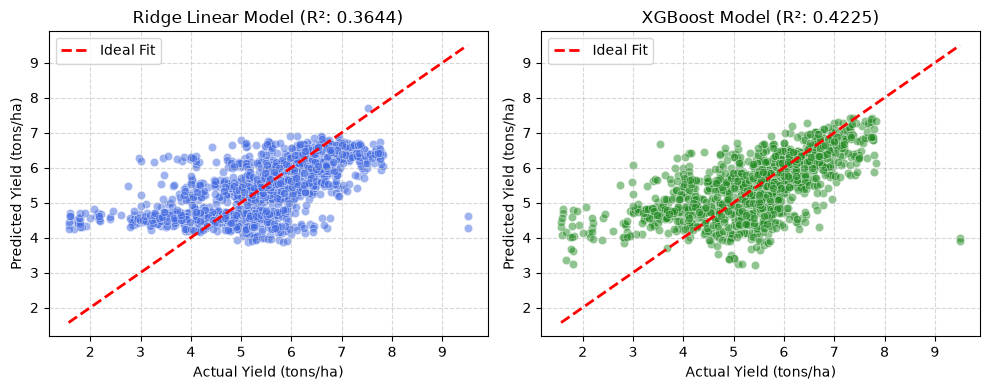

In [7]:
# 3. Plotting Actual vs. Predicted using the populated OOF arrays
plt.figure(figsize=(10, 4))

# Ridge Scatter Plot
plt.subplot(1, 2, 1)
sns.scatterplot(x=y, y=oof_preds_ridge, alpha=0.5, color='royalblue')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Ideal Fit')
plt.title(f'Ridge Linear Model (R²: {r2_score(y, oof_preds_ridge):.4f})')
plt.xlabel('Actual Yield (tons/ha)')
plt.ylabel('Predicted Yield (tons/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# XGBoost Scatter Plot
plt.subplot(1, 2, 2)
sns.scatterplot(x=y, y=oof_preds_xgb, alpha=0.5, color='forestgreen')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Ideal Fit')
plt.title(f'XGBoost Model (R²: {r2_score(y, oof_preds_xgb):.4f})')
plt.xlabel('Actual Yield (tons/ha)')
plt.ylabel('Predicted Yield (tons/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

## Hyperparameter Tuning

In [8]:
df = df[(df['yield_ton_ha'] >= 1.0) & (df['yield_ton_ha'] <= 9.5)].copy()

# Define hyperparameter grid to search
param_grid = [
    {'max_depth': 3, 'learning_rate': 0.05, 'subsample': 0.8},
    {'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8},
    {'max_depth': 5, 'learning_rate': 0.1,  'subsample': 0.8},
    {'max_depth': 7, 'learning_rate': 0.05, 'subsample': 0.9},
]

best_score = -float('inf')
best_params = None
gkf = GroupKFold(n_splits=5)

print("Running hyperparameter tuning across GroupKFold...")

# Loop through parameter combinations
for params in param_grid:
    oof_preds = np.zeros(len(df))
    
    for train_idx, test_idx in gkf.split(X, y, groups=groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        xgb = XGBRegressor(
            n_estimators=150, 
            max_depth=params['max_depth'], 
            learning_rate=params['learning_rate'], 
            subsample=params['subsample'],
            random_state=42, 
            n_jobs=-1
        )
        xgb.fit(X_train, y_train)
        oof_preds[test_idx] = xgb.predict(X_test)
        
    score = r2_score(y, oof_preds)
    print(f"Params: {params} | OOF R²: {score:.4f}")
    
    if score > best_score:
        best_score = score
        best_params = params

print(f"\nBest Hyperparameters Found: {best_params}")
print(f"Best Cross-Validated R²: {best_score:.4f}")

Running hyperparameter tuning across GroupKFold...
Params: {'max_depth': 3, 'learning_rate': 0.05, 'subsample': 0.8} | OOF R²: 0.3976
Params: {'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8} | OOF R²: 0.4081
Params: {'max_depth': 5, 'learning_rate': 0.1, 'subsample': 0.8} | OOF R²: 0.4095
Params: {'max_depth': 7, 'learning_rate': 0.05, 'subsample': 0.9} | OOF R²: 0.4166

Best Hyperparameters Found: {'max_depth': 7, 'learning_rate': 0.05, 'subsample': 0.9}
Best Cross-Validated R²: 0.4166


In [9]:
df = df[(df['yield_ton_ha'] >= 1.0) & (df['yield_ton_ha'] <= 9.5)].copy()

# Engineer interaction and non-linear features based on available columns
# (Adjust column names if your dataset uses slightly different naming)
if 'VH_mean' in df.columns and 'precip_total_mm' in df.columns:
    df['vh_precip_interaction'] = df['VH_mean'] * df['precip_total_mm']

if 'temp_mean_c' in df.columns:
    df['temp_mean_squared'] = df['temp_mean_c'] ** 2

target_col = 'yield_ton_ha'
cols_to_exclude = [target_col, 'production_tons', 'planted_area_ha', 'year']

X_raw = df.drop(columns=[col for col in cols_to_exclude if col in df.columns])
y = df[target_col]
groups = df['province_name']

categorical_cols = ['province_name', 'macro_region', 'season']
X = pd.get_dummies(X_raw, columns=[col for col in categorical_cols if col in X_raw.columns], drop_first=True)
X = X.fillna(X.mean())

# Evaluate with GroupKFold using XGBoost
oof_preds_xgb = np.zeros(len(df))
gkf = GroupKFold(n_splits=5)

for train_idx, test_idx in gkf.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, n_jobs=-1)
    xgb.fit(X_train, y_train)
    oof_preds_xgb[test_idx] = xgb.predict(X_test)

print(f"New XGBoost GroupKFold R² (with interactions): {r2_score(y, oof_preds_xgb):.4f}")

New XGBoost GroupKFold R² (with interactions): 0.4158


## Features

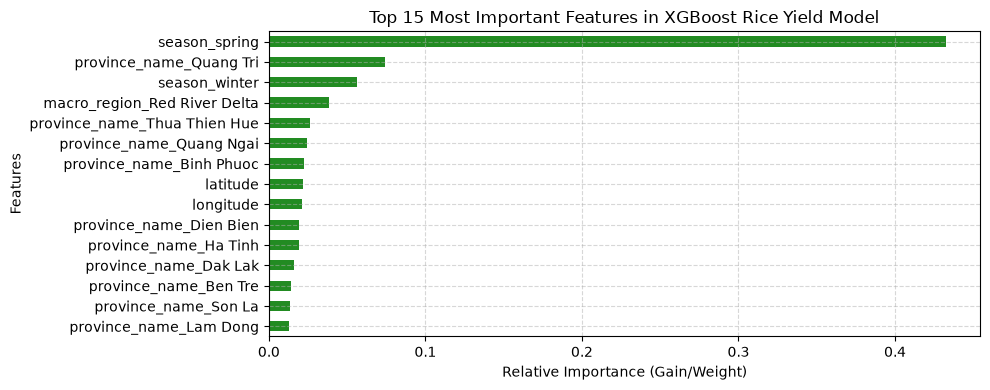

In [20]:
df = df[(df['yield_ton_ha'] >= 1.0) & (df['yield_ton_ha'] <= 9.5)].copy()

target_col = 'yield_ton_ha'
cols_to_exclude = [target_col, 'production_tons', 'planted_area_ha', 'year']

X_raw = df.drop(columns=[col for col in cols_to_exclude if col in df.columns])
y = df[target_col]

categorical_cols = ['province_name', 'macro_region', 'season']
X = pd.get_dummies(X_raw, columns=[col for col in categorical_cols if col in X_raw.columns], drop_first=True)
X = X.fillna(X.mean())

# Train a full model on all cleaned data
final_model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, n_jobs=-1)
final_model.fit(X, y)

# Extract and sort feature importances manually
importances = pd.Series(final_model.feature_importances_, index=X.columns)
top_15 = importances.nlargest(15)

# Plot Top 15 Feature Importances
plt.figure(figsize=(10, 4))
top_15.sort_values().plot(kind='barh', color='forestgreen')
plt.title('Top 15 Most Important Features in XGBoost Rice Yield Model')
plt.xlabel('Relative Importance (Gain/Weight)')
plt.ylabel('Features')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [12]:
df = df[(df['yield_ton_ha'] >= 1.0) & (df['yield_ton_ha'] <= 9.5)].copy()

target_col = 'yield_ton_ha'
cols_to_exclude = [target_col, 'production_tons', 'planted_area_ha', 'year']

X_raw = df.drop(columns=[col for col in cols_to_exclude if col in df.columns])
y = df[target_col]
groups = df['province_name']  # Still used strictly for GroupKFold validation spliting!

# One-hot encode ONLY macro_region and season (EXCLUDING province_name as a feature)
categorical_cols = ['macro_region', 'season']
X = pd.get_dummies(X_raw, columns=[col for col in categorical_cols if col in X_raw.columns], drop_first=True)

# Drop text-based province column if present
if 'province_name' in X.columns:
    X = X.drop(columns=['province_name'])

X = X.fillna(X.mean())

# Evaluate with GroupKFold using XGBoost
oof_preds_xgb = np.zeros(len(df))
gkf = GroupKFold(n_splits=5)

for train_idx, test_idx in gkf.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, n_jobs=-1)
    xgb.fit(X_train, y_train)
    oof_preds_xgb[test_idx] = xgb.predict(X_test)

print(f"\n=== Results Without Province Dummies ===")
print(f"XGBoost GroupKFold R²: {r2_score(y, oof_preds_xgb):.4f}\n")


=== Results Without Province Dummies ===
XGBoost GroupKFold R²: 0.3681



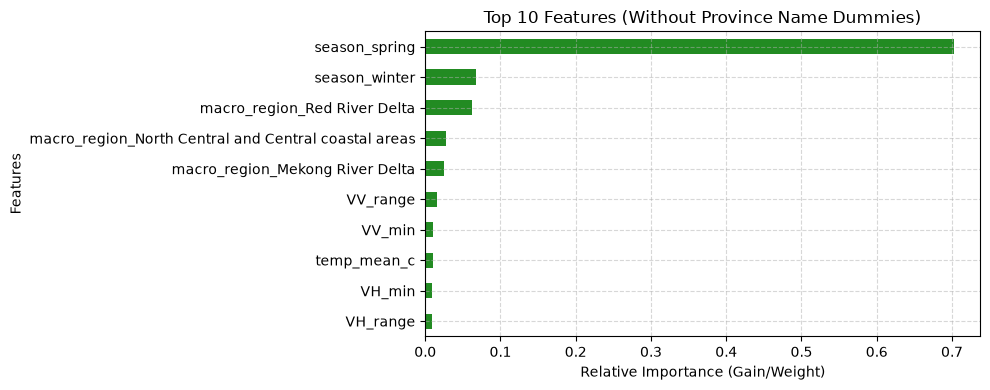

In [15]:
# 4. Train a full model to check what features take over the top spots
final_model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, n_jobs=-1)
final_model.fit(X, y)

importances = pd.Series(final_model.feature_importances_, index=X.columns)
top_15 = importances.nlargest(10)

# 5. Plot New Top 15 Feature Importances
plt.figure(figsize=(10, 4))
top_15.sort_values().plot(kind='barh', color='forestgreen')
plt.title('Top 10 Features (Without Province Name Dummies)')
plt.xlabel('Relative Importance (Gain/Weight)')
plt.ylabel('Features')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Add spatial coordinates

In [16]:
print([col for col in df.columns if 'lat' in col.lower() or 'lon' in col.lower() or 'coord' in col.lower() or 'geo' in col.lower()])

[]


In [17]:
df = df[(df['yield_ton_ha'] >= 1.0) & (df['yield_ton_ha'] <= 9.5)].copy()

# regional coordinate lookup for Vietnam's main agricultural hubs
province_coords = {
    # Mekong Delta (Key Rice Basket)
    'An Giang': (10.5255, 105.4255), 'Can Tho': (10.0452, 105.7469),
    'Dong Thap': (10.4579, 105.6732), 'Long An': (10.5356, 106.4109),
    'Soc Trang': (9.6037, 105.9743), 'Kien Giang': (10.0121, 105.0809),
    'Tien Giang': (10.3814, 106.2353), 'Hau Giang': (9.7829, 105.4722),
    'Tra Vinh': (9.9369, 106.3411), 'Vinh Long': (10.2537, 105.9723),
    'Bac Lieu': (9.2940, 105.7278), 'Ca Mau': (9.1769, 105.1524),
    'Ben Tre': (10.2430, 106.3756),
    
    # Red River Delta (Northern Rice Basket)
    'Thai Binh': (20.4463, 106.3366), 'Nam Dinh': (20.4357, 106.1684),
    'Hai Duong': (20.9367, 106.3314), 'Ha Noi': (21.0285, 105.8542),
    'Ha Nam': (20.5833, 105.9167), 'Hung Yen': (20.6464, 106.0511),
    'Ninh Binh': (20.2581, 105.9797), 'Thai Nguyen': (21.5940, 105.8481),
    'Bac Ninh': (21.1861, 106.0763), 'Vinh Phuc': (21.3089, 105.6042),
    'Hai Phong': (20.8449, 106.6881),
    
    # Central & Highlands Regions
    'Thanh Hoa': (19.8067, 105.7852), 'Nghe An': (18.6796, 105.6813),
    'Ha Tinh': (18.3429, 105.9055), 'Quang Binh': (17.4777, 106.6025),
    'Quang Tri': (16.7499, 107.1856), 'Thua Thien Hue': (16.4637, 107.5909),
    'Quang Nam': (15.5558, 108.4725), 'Quang Ngai': (15.1206, 108.7922),
    'Binh Dinh': (13.7820, 109.2197), 'Phu Yen': (13.0884, 109.3097),
    'Khanh Hoa': (12.2388, 109.1967), 'Ninh Thuan': (11.5643, 108.9886),
    'Binh Thuan': (10.9275, 108.0987), 'Dak Lak': (12.6667, 108.0333),
    'Lam Dong': (11.9404, 108.4383)
}

# Map latitude/longitude, defaulting to central Vietnam coordinates (16.0, 108.0) if unmatched
df['latitude'] = df['province_name'].map(lambda p: province_coords.get(p, (16.0, 108.0))[0])
df['longitude'] = df['province_name'].map(lambda p: province_coords.get(p, (16.0, 108.0))[1])

target_col = 'yield_ton_ha'
cols_to_exclude = [target_col, 'production_tons', 'planted_area_ha', 'year']

X_raw = df.drop(columns=[col for col in cols_to_exclude if col in df.columns])
y = df[target_col]
groups = df['province_name']  # Rigorous spatial splitting group

# One-hot encode macro_region and season (excluding province name)
categorical_cols = ['macro_region', 'season']
X = pd.get_dummies(X_raw, columns=[col for col in categorical_cols if col in X_raw.columns], drop_first=True)

if 'province_name' in X.columns:
    X = X.drop(columns=['province_name'])

X = X.fillna(X.mean())

# Evaluate with GroupKFold using XGBoost
oof_preds_xgb = np.zeros(len(df))
gkf = GroupKFold(n_splits=5)

for train_idx, test_idx in gkf.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, n_jobs=-1)
    xgb.fit(X_train, y_train)
    oof_preds_xgb[test_idx] = xgb.predict(X_test)

print(f"\n=== Results With Mapped Lat/Long Spatial Coordinates ===")
print(f"XGBoost GroupKFold R²: {r2_score(y, oof_preds_xgb):.4f}\n")


=== Results With Mapped Lat/Long Spatial Coordinates ===
XGBoost GroupKFold R²: 0.4021



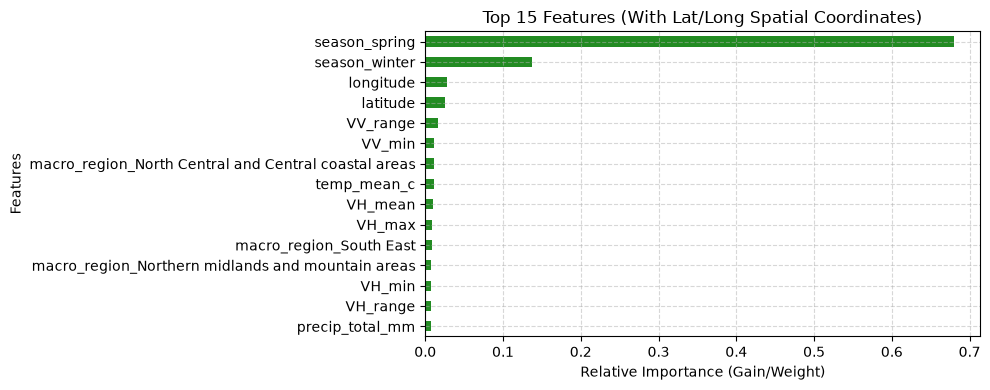

In [19]:
# 1. Train full model on the coordinate-augmented dataset (using the same feature prep logic)
final_model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, n_jobs=-1)
final_model.fit(X, y)

# 2. Extract and sort feature importances
importances = pd.Series(final_model.feature_importances_, index=X.columns)
top_15 = importances.nlargest(15)

# 3. Plot Top 15 Feature Importances
plt.figure(figsize=(10, 4))
top_15.sort_values().plot(kind='barh', color='forestgreen')
plt.title('Top 15 Features (With Lat/Long Spatial Coordinates)')
plt.xlabel('Relative Importance (Gain/Weight)')
plt.ylabel('Features')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import GridSearchCV

# 1. Define the hyperparameter search space
param_grid = {
    'max_depth': [4, 5, 6, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.9, 1.0]
}

# 2. Instantiate the base XGBoost regressor
xgb_base = XGBRegressor(n_estimators=150, random_state=42, n_jobs=-1)

# 3. Setup GridSearchCV using the splitter object directly (NOT .split())
gkf = GroupKFold(n_splits=5)
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring='r2',
    cv=gkf,                  # Pass the object here
    n_jobs=-1,
    verbose=1
)

# 4. Run the search, passing groups explicitly into fit()
grid_search.fit(X, y, groups=groups)

print("\n=== Tuning Complete ===")
print("Best Hyperparameters Found:", grid_search.best_params_)
print(f"Best Spatially-Validated GroupKFold R²: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits

=== Tuning Complete ===
Best Hyperparameters Found: {'colsample_bytree': 0.7, 'learning_rate': 0.03, 'max_depth': 7, 'subsample': 1.0}
Best Spatially-Validated GroupKFold R²: 0.4693
